# Experiments 001 to 004: subject accuracy and tier validation

This notebook compares per-subject MMLU accuracy across every full experiment and checks whether the proposed easy, medium and hard tiers match the observed difficulty.

It is separate from `004_1_analysis_plots.ipynb`, which remains the RQ3 analysis of SFT-to-GRPO versus base-to-GRPO at 3B. This notebook reads saved artifacts only and does not need a GPU. Figures are saved to `analysis/figures/004_2/`.

In [1]:
# find the repo root and set up the separate subject-analysis figure folder
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "config.py").exists():
    raise FileNotFoundError("I could not find the repository root containing config.py")
sys.path.insert(0, str(ROOT))

from analysis.plotting import heatmap_text_color

RES = ROOT / "results"
R3 = RES / "003_COLAB_FULL_B3_sft_grpo_seed0"
B3 = RES / "base_evals" / "003_COLAB_FULL_B3"
R4 = RES / "004_COLAB_FULL_B3_base_grpo_seed0"
B4 = RES / "base_evals" / "004_COLAB_FULL_B3"
FIG = ROOT / "analysis" / "figures" / "004_2"
FIG.mkdir(parents=True, exist_ok=True)

plt.style.use("default")

def jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")
    print("saved", name)

print("figures ->", FIG)

figures -> /Users/oleggastov/Desktop/University UK/0006_City n St Georges Universities/003_Projects/INM363-IndividualProject-Dissertation/001_Code/analysis/figures/004_2


## Analysis scope

The original study plan called for checking the initial easy, medium and hard groupings
against zero-shot accuracy from the pilot base models. This section checks the groupings
using the saved predictions from each full run.

Two measurements are kept separate. Generative exact-match is the registered primary
metric, but it also includes prompt following, tag completion and extraction. The
log-probability probe is format-neutral and is therefore the stronger robustness check
for whether a subject is difficult because the base model lacks the answer knowledge.

The local smoke runs are excluded because they use a tiny stand-in model and four items
per subject. Experiment 001 is shown for completeness but is not pooled with 002 because
001 used the 384-token, no-prefill protocol and 002 used the amended 512-token prefill.

In [2]:
# load every full experiment and keep its protocol and training stage visible
from data.subjects import TIERS as SUBJECT_TIERS
from scipy.stats import spearmanr
import pandas as pd

SUBJECTS = [subject for tier in ["easy", "medium", "hard"]
            for subject in SUBJECT_TIERS[tier]]
SUBJECT_TIER = {subject: tier for tier, members in SUBJECT_TIERS.items()
                for subject in members}
SUBJECT_LABELS = {
    "high_school_psychology": "HS psychology",
    "marketing": "marketing",
    "business_ethics": "business ethics",
    "high_school_geography": "HS geography",
    "philosophy": "philosophy",
    "us_foreign_policy": "US foreign policy",
    "high_school_mathematics": "HS mathematics",
    "formal_logic": "formal logic",
}

R1 = RES / "001_COLAB_FULL_B05_sft_grpo_seed0"
B1 = RES / "base_evals" / "001_COLAB_FULL_B05"
R2 = RES / "002_COLAB_FULL_B05_sft_grpo_seed0"
B2 = RES / "base_evals" / "002_COLAB_FULL_B05"

RUN_SPECS = [
    ("001", "0.5B", "384, no think prefill", [
        ("base", B1 / "base_preds.jsonl", B1 / "base_logprob_preds.jsonl"),
        ("SFT", R1 / "sft_preds.jsonl", R1 / "sft_logprob_preds.jsonl"),
        ("SFT+GRPO", R1 / "grpo_preds.jsonl", R1 / "grpo_logprob_preds.jsonl"),
    ]),
    ("002", "0.5B", "512, think prefill", [
        ("base", B2 / "base_preds.jsonl", B2 / "base_logprob_preds.jsonl"),
        ("SFT", R2 / "sft_preds.jsonl", R2 / "sft_logprob_preds.jsonl"),
        ("SFT+GRPO", R2 / "grpo_preds.jsonl", R2 / "grpo_logprob_preds.jsonl"),
    ]),
    ("003", "3B", "512, think prefill", [
        ("base", B3 / "base_preds.jsonl", B3 / "base_logprob_preds.jsonl"),
        ("SFT", R3 / "sft_preds.jsonl", R3 / "sft_logprob_preds.jsonl"),
        ("SFT+GRPO", R3 / "grpo_preds.jsonl", R3 / "grpo_logprob_preds.jsonl"),
    ]),
    ("004", "3B", "512, think prefill", [
        ("base", B4 / "base_preds.jsonl", B4 / "base_logprob_preds.jsonl"),
        ("base+GRPO", R4 / "grpo_preds.jsonl", R4 / "grpo_logprob_preds.jsonl"),
    ]),
]

SOURCE_ROWS = {}
subject_records = []
ROW_ORDER = []
reference_keys = None

for experiment, scale, protocol, stages in RUN_SPECS:
    for stage, gen_path, probe_path in stages:
        row_label = f"{experiment} | {scale} | {stage}"
        ROW_ORDER.append(row_label)
        for metric, path in [("generative", gen_path), ("probe", probe_path)]:
            rows = jsonl(path)
            keys = [(row["subject"], row["gold"]) for row in rows]
            if len(rows) != 1884:
                raise ValueError(f"I expected 1884 rows in {path}, found {len(rows)}")
            if reference_keys is None:
                reference_keys = keys
            elif keys != reference_keys:
                raise ValueError(f"I found misaligned test items in {path}")
            SOURCE_ROWS[(experiment, stage, metric)] = rows
            for subject in SUBJECTS:
                values = [int(row["correct"]) for row in rows
                          if row["subject"] == subject]
                if not values:
                    raise ValueError(f"I found no rows for {subject} in {path}")
                subject_records.append({
                    "experiment": experiment,
                    "scale": scale,
                    "protocol": protocol,
                    "stage": stage,
                    "row_label": row_label,
                    "metric": metric,
                    "subject": subject,
                    "tier": SUBJECT_TIER[subject],
                    "n": len(values),
                    "correct": int(sum(values)),
                    "accuracy": float(np.mean(values)),
                })

SUBJECT_DF = pd.DataFrame(subject_records)
print(f"loaded {len(SOURCE_ROWS)} aligned prediction files")
display(SUBJECT_DF[SUBJECT_DF["metric"] == "generative"]
        .drop_duplicates("subject")[["subject", "tier", "n"]]
        .set_index("subject"))

loaded 22 aligned prediction files


,tier,n
subject,,
high_school_psychology,easy,545
marketing,easy,234
us_foreign_policy,easy,100
high_school_geography,medium,198
philosophy,medium,311
business_ethics,medium,100
high_school_mathematics,hard,270
formal_logic,hard,126


subject,HS psychology,marketing,US foreign policy,HS geography,philosophy,business ethics,HS mathematics,formal logic
row_label,,,,,,,,
001 | 0.5B | base,32.3,30.8,31.0,31.8,27.3,26.0,7.8,29.4
001 | 0.5B | SFT,26.8,33.3,36.0,32.3,19.6,30.0,22.6,21.4
001 | 0.5B | SFT+GRPO,26.1,32.1,27.0,23.2,21.2,29.0,22.6,23.0
002 | 0.5B | base,20.2,19.7,28.0,13.6,17.7,14.0,8.1,16.7
002 | 0.5B | SFT,24.8,24.4,31.0,23.7,21.5,25.0,19.6,18.3
002 | 0.5B | SFT+GRPO,62.2,75.2,72.0,58.1,48.2,46.0,23.3,33.3
003 | 3B | base,67.7,70.9,63.0,53.0,51.4,59.0,51.9,44.4
003 | 3B | SFT,67.5,51.3,54.0,55.1,43.1,47.0,46.3,38.9
003 | 3B | SFT+GRPO,84.0,82.1,79.0,68.7,66.2,72.0,54.4,46.8


saved fig15_subject_accuracy_all_experiments


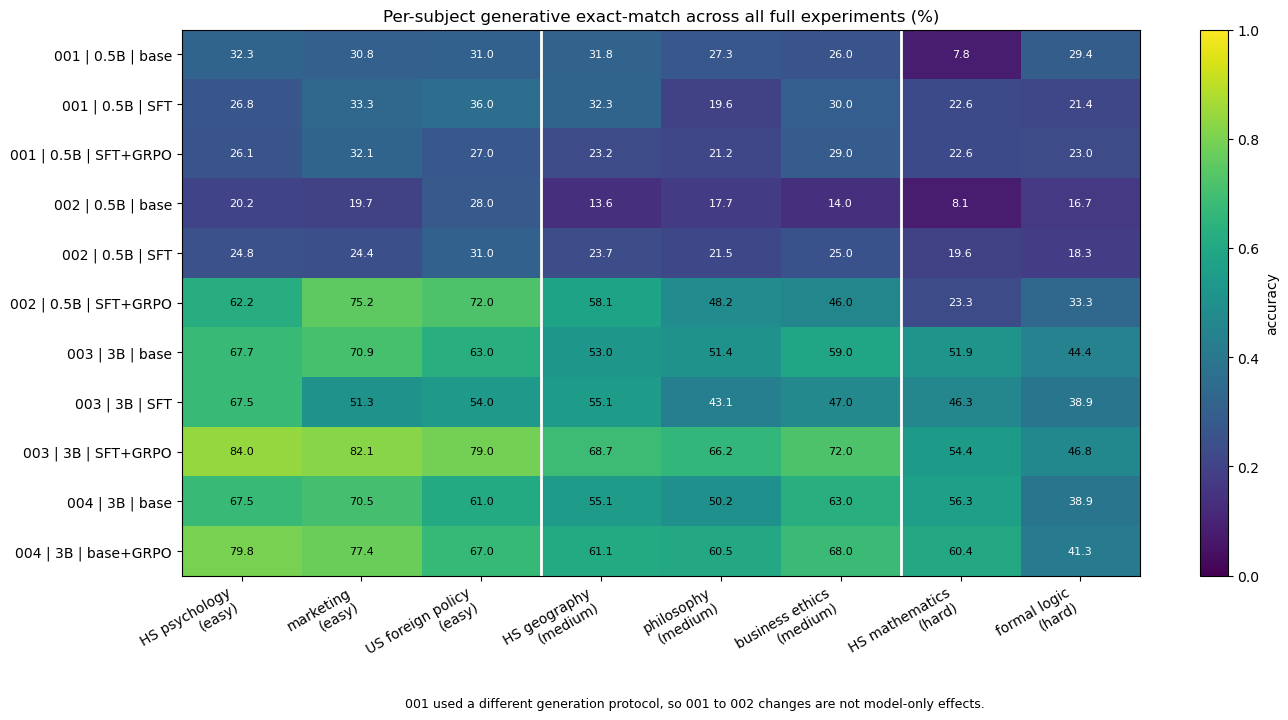

In [3]:
# start with one matrix that contains every generative experiment stage
gen_matrix = (SUBJECT_DF[SUBJECT_DF["metric"] == "generative"]
              .pivot(index="row_label", columns="subject", values="accuracy")
              .reindex(index=ROW_ORDER, columns=SUBJECTS))

display((100 * gen_matrix).round(1).rename(
    columns={subject: SUBJECT_LABELS[subject] for subject in SUBJECTS}))

fig, ax = plt.subplots(figsize=(14, 7.2))
image = ax.imshow(gen_matrix.to_numpy(), aspect="auto", cmap="viridis",
                  vmin=0, vmax=1)
for row_index in range(gen_matrix.shape[0]):
    for col_index in range(gen_matrix.shape[1]):
        value = gen_matrix.iloc[row_index, col_index]
        text_color = heatmap_text_color(image, value)
        ax.text(col_index, row_index, f"{100 * value:.1f}", ha="center",
                va="center", color=text_color, fontsize=8)
xlabels = [f"{SUBJECT_LABELS[subject]}\n({SUBJECT_TIER[subject]})"
           for subject in SUBJECTS]
ax.set_xticks(np.arange(len(SUBJECTS)))
ax.set_xticklabels(xlabels, rotation=30, ha="right")
ax.set_yticks(np.arange(len(ROW_ORDER)))
ax.set_yticklabels(ROW_ORDER)
ax.grid(False)
ax.axvline(2.5, color="white", lw=2)
ax.axvline(5.5, color="white", lw=2)
ax.set_title("Per-subject generative exact-match across all full experiments (%)")
fig.colorbar(image, ax=ax, label="accuracy")
fig.text(0.5, 0.01,
         "001 used a different generation protocol, so 001 to 002 changes are not model-only effects.",
         ha="center", fontsize=9)
fig.tight_layout(rect=[0, 0.04, 1, 1])
save(fig, "fig15_subject_accuracy_all_experiments")
plt.show()

saved fig16_subject_final_endpoints_all_experiments


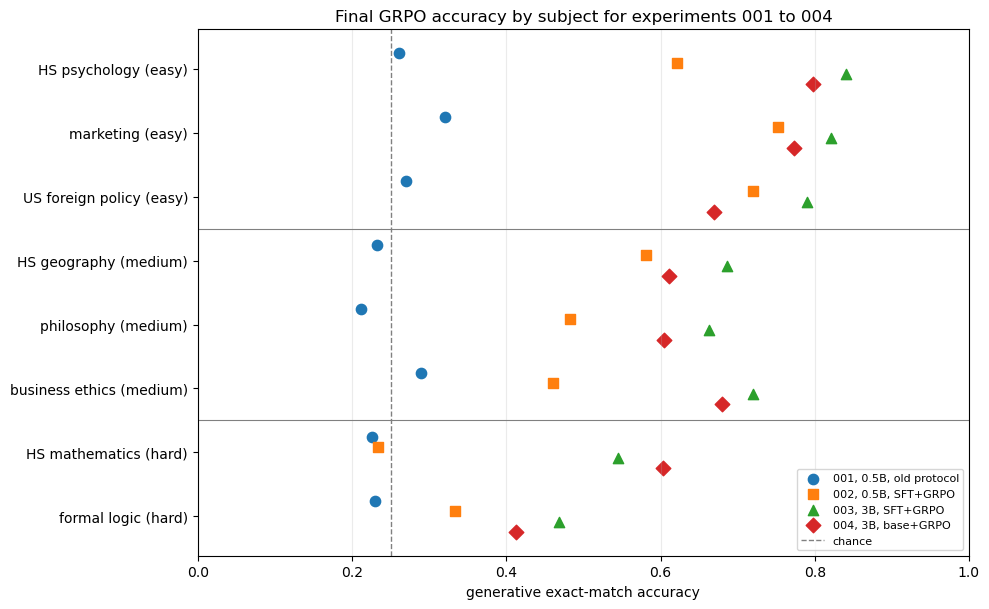

In [4]:
# compare the four final GRPO endpoints without hiding the subject variation
FINAL_SOURCES = [
    ("001 | 0.5B | SFT+GRPO", "001, 0.5B, old protocol", "o", "tab:blue"),
    ("002 | 0.5B | SFT+GRPO", "002, 0.5B, SFT+GRPO", "s", "tab:orange"),
    ("003 | 3B | SFT+GRPO", "003, 3B, SFT+GRPO", "^", "tab:green"),
    ("004 | 3B | base+GRPO", "004, 3B, base+GRPO", "D", "tab:red"),
]
ypos = np.arange(len(SUBJECTS))
offsets = np.linspace(-0.24, 0.24, len(FINAL_SOURCES))
fig, ax = plt.subplots(figsize=(10, 6.2))
for offset, (row_label, label, marker, color) in zip(offsets, FINAL_SOURCES):
    values = (gen_matrix.loc[row_label, SUBJECTS]).to_numpy()
    ax.scatter(values, ypos + offset, s=55, marker=marker, label=label, color=color)
ax.axvline(0.25, color="grey", ls="--", lw=1, label="chance")
ax.axhline(2.5, color="grey", lw=0.8)
ax.axhline(5.5, color="grey", lw=0.8)
ax.set_yticks(ypos)
ax.set_yticklabels([f"{SUBJECT_LABELS[s]} ({SUBJECT_TIER[s]})" for s in SUBJECTS])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("generative exact-match accuracy")
ax.set_title("Final GRPO accuracy by subject for experiments 001 to 004")
ax.grid(alpha=0.25, axis="x")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
save(fig, "fig16_subject_final_endpoints_all_experiments")
plt.show()

saved fig17_base_subject_difficulty_generation_vs_probe


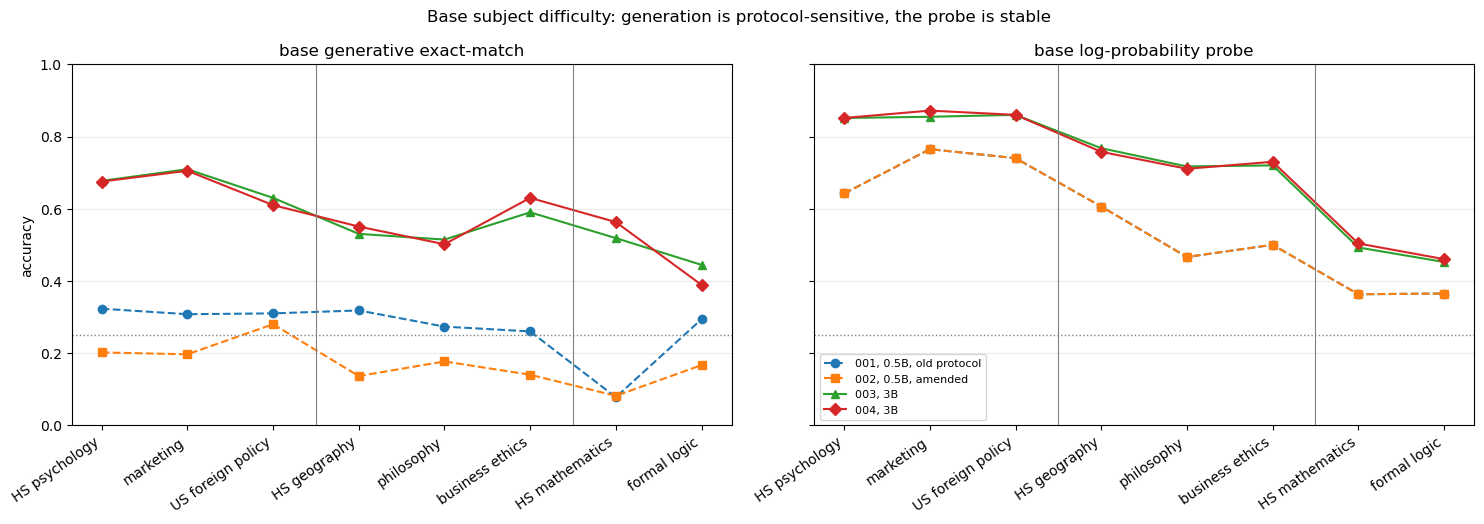

,same_prediction,same_correctness
comparison,,
"0.5B base probe, 001 vs 002",1.0000,1.0000
"3B base generation, 003 vs 004",0.8355,0.8891
"3B base probe, 003 vs 004",0.9862,0.9899


In [5]:
# compare base generation with the format-neutral base knowledge probe
BASE_SOURCES = [
    ("001 | 0.5B | base", "001, 0.5B, old protocol", "o", "--", "tab:blue"),
    ("002 | 0.5B | base", "002, 0.5B, amended", "s", "--", "tab:orange"),
    ("003 | 3B | base", "003, 3B", "^", "-", "tab:green"),
    ("004 | 3B | base", "004, 3B", "D", "-", "tab:red"),
]
xpos = np.arange(len(SUBJECTS))
fig, axes = plt.subplots(1, 2, figsize=(15, 5.3), sharey=True)
for ax, metric, title in [
    (axes[0], "generative", "base generative exact-match"),
    (axes[1], "probe", "base log-probability probe"),
]:
    metric_frame = (SUBJECT_DF[SUBJECT_DF["metric"] == metric]
                    .pivot(index="row_label", columns="subject", values="accuracy"))
    for row_label, label, marker, line_style, color in BASE_SOURCES:
        values = metric_frame.loc[row_label, SUBJECTS].to_numpy()
        ax.plot(xpos, values, marker=marker, ls=line_style, label=label, color=color)
    ax.axhline(0.25, color="grey", ls=":", lw=1)
    ax.axvline(2.5, color="grey", lw=0.8)
    ax.axvline(5.5, color="grey", lw=0.8)
    ax.set_xticks(xpos)
    ax.set_xticklabels([SUBJECT_LABELS[s] for s in SUBJECTS], rotation=35, ha="right")
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.grid(alpha=0.25, axis="y")
axes[0].set_ylabel("accuracy")
axes[1].legend(fontsize=8, loc="lower left")
fig.suptitle("Base subject difficulty: generation is protocol-sensitive, the probe is stable")
fig.tight_layout()
save(fig, "fig17_base_subject_difficulty_generation_vs_probe")
plt.show()

# measure repeated-base agreement before treating small rank changes as real
def row_agreement(rows_a, rows_b):
    if [(r["subject"], r["gold"]) for r in rows_a] != [
            (r["subject"], r["gold"]) for r in rows_b]:
        raise ValueError("I found base files with different item alignment")
    return {
        "same_prediction": np.mean([a["pred"] == b["pred"]
                                    for a, b in zip(rows_a, rows_b)]),
        "same_correctness": np.mean([bool(a["correct"]) == bool(b["correct"])
                                     for a, b in zip(rows_a, rows_b)]),
    }

agreement_rows = []
for label, source_a, source_b in [
    ("0.5B base probe, 001 vs 002", ("001", "base", "probe"),
     ("002", "base", "probe")),
    ("3B base generation, 003 vs 004", ("003", "base", "generative"),
     ("004", "base", "generative")),
    ("3B base probe, 003 vs 004", ("003", "base", "probe"),
     ("004", "base", "probe")),
]:
    agreement_rows.append({"comparison": label,
                           **row_agreement(SOURCE_ROWS[source_a], SOURCE_ROWS[source_b])})
agreement_tbl = pd.DataFrame(agreement_rows).set_index("comparison")
display(agreement_tbl.round(4))

In [6]:
# quantify tier ordering with equal subject weight so psychology does not dominate
SOURCE_DEFS = [
    ("001 base gen", "001 | 0.5B | base", "generative"),
    ("001 base probe", "001 | 0.5B | base", "probe"),
    ("001 final gen", "001 | 0.5B | SFT+GRPO", "generative"),
    ("002 base gen", "002 | 0.5B | base", "generative"),
    ("002 base probe", "002 | 0.5B | base", "probe"),
    ("002 final gen", "002 | 0.5B | SFT+GRPO", "generative"),
    ("003 base gen", "003 | 3B | base", "generative"),
    ("003 base probe", "003 | 3B | base", "probe"),
    ("003 final gen", "003 | 3B | SFT+GRPO", "generative"),
    ("004 base gen", "004 | 3B | base", "generative"),
    ("004 base probe", "004 | 3B | base", "probe"),
    ("004 final gen", "004 | 3B | base+GRPO", "generative"),
]

def accuracy_map(row_label, metric):
    subset = SUBJECT_DF[(SUBJECT_DF["row_label"] == row_label)
                        & (SUBJECT_DF["metric"] == metric)]
    return dict(zip(subset["subject"], subset["accuracy"]))

def pair_order_rate(acc, easier_tier, harder_tier, mapping=SUBJECT_TIERS):
    comparisons = [acc[easier] > acc[harder]
                   for easier in mapping[easier_tier]
                   for harder in mapping[harder_tier]]
    return float(np.mean(comparisons))

tier_rows = []
tier_codes = {"easy": 0, "medium": 1, "hard": 2}
for label, row_label, metric in SOURCE_DEFS:
    acc = accuracy_map(row_label, metric)
    difficulty = [1 - acc[subject] for subject in SUBJECTS]
    assigned = [tier_codes[SUBJECT_TIER[subject]] for subject in SUBJECTS]
    rho, p_value = spearmanr(assigned, difficulty)
    tier_rows.append({
        "source": label,
        "easy_macro": np.mean([acc[s] for s in SUBJECT_TIERS["easy"]]),
        "medium_macro": np.mean([acc[s] for s in SUBJECT_TIERS["medium"]]),
        "hard_macro": np.mean([acc[s] for s in SUBJECT_TIERS["hard"]]),
        "easy>medium pairs": pair_order_rate(acc, "easy", "medium"),
        "medium>hard pairs": pair_order_rate(acc, "medium", "hard"),
        "easy>hard pairs": pair_order_rate(acc, "easy", "hard"),
        "easy-hard boundary": min(acc[s] for s in SUBJECT_TIERS["easy"])
                              - max(acc[s] for s in SUBJECT_TIERS["hard"]),
        "spearman_rho": rho,
        "spearman_p": p_value,
    })

tier_validation_tbl = pd.DataFrame(tier_rows).set_index("source")
display(tier_validation_tbl.round(3))

,easy_macro,medium_macro,hard_macro,easy>medium pairs,medium>hard pairs,easy>hard pairs,easy-hard boundary,spearman_rho,spearman_p
source,,,,,,,,,
001 base gen,0.314,0.284,0.186,0.778,0.667,1.0,0.014,0.668,0.070
001 base probe,0.716,0.524,0.364,1.000,1.000,1.0,0.277,0.945,0.000
001 final gen,0.284,0.245,0.228,0.778,0.667,1.0,0.030,0.668,0.070
002 base gen,0.226,0.151,0.124,1.000,0.667,1.0,0.030,0.819,0.013
002 base probe,0.716,0.524,0.364,1.000,1.000,1.0,0.277,0.945,0.000
002 final gen,0.698,0.508,0.283,1.000,1.000,1.0,0.289,0.945,0.000
003 base gen,0.672,0.545,0.481,1.000,0.833,1.0,0.111,0.882,0.004
003 base probe,0.855,0.735,0.472,1.000,1.000,1.0,0.359,0.945,0.000
003 final gen,0.817,0.690,0.506,1.000,1.000,1.0,0.246,0.945,0.000


,metric,delta,ci_lo,ci_hi
source,,,,
001 gen,generative,-0.0337,-0.1495,0.0857
001 probe,probe,0.1349,0.0073,0.2629
002 gen,generative,-0.0267,-0.1188,0.0671
002 probe,probe,0.1349,0.0073,0.2629
003 gen,generative,0.1456,0.0176,0.2732
003 probe,probe,0.2676,0.1438,0.3890
004 gen,generative,0.2411,0.1138,0.3649
004 probe,probe,0.2697,0.1462,0.3908


saved fig18_easy_hard_boundary_bootstrap


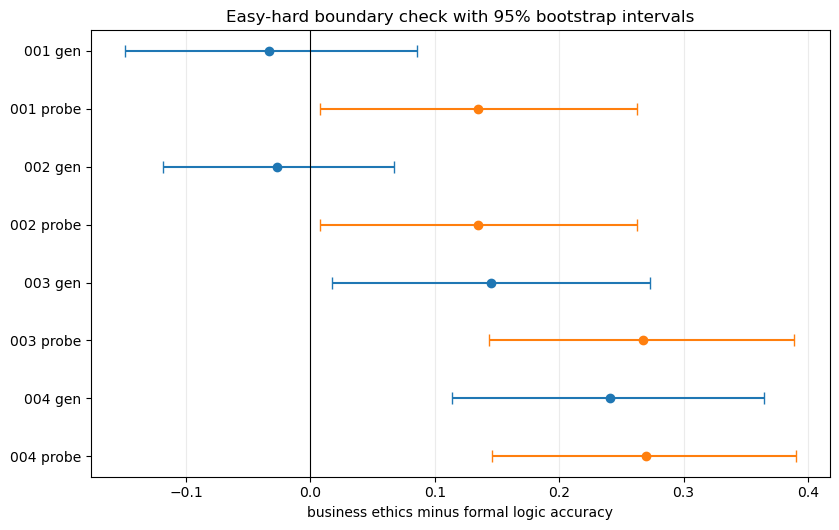

In [7]:
# test the closest easy-hard boundary with an independent item bootstrap
def independent_subject_delta_ci(rows, subject_a, subject_b, n_boot=20000, seed=0):
    values_a = np.asarray([int(row["correct"]) for row in rows
                           if row["subject"] == subject_a], dtype=float)
    values_b = np.asarray([int(row["correct"]) for row in rows
                           if row["subject"] == subject_b], dtype=float)
    rng = np.random.default_rng(seed)
    boot_a = values_a[rng.integers(0, len(values_a), size=(n_boot, len(values_a)))].mean(1)
    boot_b = values_b[rng.integers(0, len(values_b), size=(n_boot, len(values_b)))].mean(1)
    boot_delta = boot_a - boot_b
    return (float(values_a.mean() - values_b.mean()),
            float(np.percentile(boot_delta, 2.5)),
            float(np.percentile(boot_delta, 97.5)))

boundary_rows = []
for experiment in ["001", "002", "003", "004"]:
    for metric, short in [("generative", "gen"), ("probe", "probe")]:
        delta, lo, hi = independent_subject_delta_ci(
            SOURCE_ROWS[(experiment, "base", metric)],
            "business_ethics", "formal_logic", seed=0)
        boundary_rows.append({
            "source": f"{experiment} {short}",
            "metric": metric,
            "delta": delta,
            "ci_lo": lo,
            "ci_hi": hi,
        })

boundary_tbl = pd.DataFrame(boundary_rows).set_index("source")
display(boundary_tbl.round(4))

fig, ax = plt.subplots(figsize=(8.5, 5.4))
for index, (source, row) in enumerate(boundary_tbl.iterrows()):
    color = "tab:blue" if row["metric"] == "generative" else "tab:orange"
    ax.errorbar(row["delta"], index,
                xerr=np.array([[row["delta"] - row["ci_lo"]],
                               [row["ci_hi"] - row["delta"]]]),
                fmt="o", capsize=4, color=color)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(np.arange(len(boundary_tbl)))
ax.set_yticklabels(boundary_tbl.index)
ax.invert_yaxis()
ax.set_xlabel("business ethics minus formal logic accuracy")
ax.set_title("Easy-hard boundary check with 95% bootstrap intervals")
ax.grid(alpha=0.25, axis="x")
fig.tight_layout()
save(fig, "fig18_easy_hard_boundary_bootstrap")
plt.show()

,metric,delta,ci_lo,ci_hi
source,,,,
002 gen,generative,0.14,0.03,0.25
002 probe,probe,0.24,0.11,0.37
003 gen,generative,0.04,-0.10,0.17
003 probe,probe,0.14,0.03,0.25
004 gen,generative,-0.02,-0.15,0.12
004 probe,probe,0.13,0.02,0.24


saved fig19_easy_medium_membership_swap


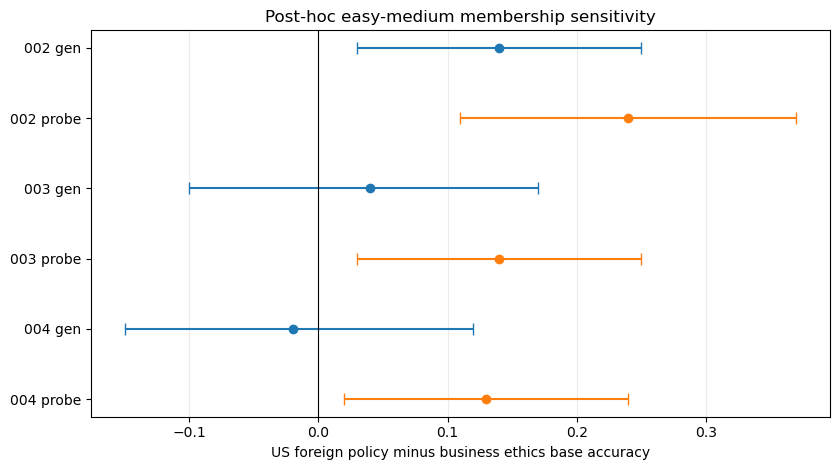

easy_macro  medium_macro  hard_macro  \
source    mapping                                               
002 gen   proposal            0.226         0.151       0.124   
          post-hoc swap       0.226         0.151       0.124   
002 probe proposal            0.716         0.524       0.364   
          post-hoc swap       0.716         0.524       0.364   
003 gen   proposal            0.672         0.545       0.481   
          post-hoc swap       0.672         0.545       0.481   
003 probe proposal            0.855         0.735       0.472   
          post-hoc swap       0.855         0.735       0.472   
004 gen   proposal            0.663         0.561       0.476   
          post-hoc swap       0.663         0.561       0.476   
004 probe proposal            0.861         0.733       0.482   
          post-hoc swap       0.861         0.733       0.482   

                         easy>medium pairs  medium>hard pairs  easy>hard pairs  
source    mapping                                                               
002 gen   proposal                   1.000              0.667              1.0  
          post-hoc swap              1.000              0.667              1.0  
002 probe proposal                   1.000              1.000              1.0  
          post-hoc swap              1.000              1.000              1.0  
003 gen   proposal                   1.000              0.833              1.0  
          post-hoc swap              1.000              0.833              1.0  
003 probe proposal                   1.000              1.000              1.0  
          post-hoc swap              1.000              1.000              1.0  
004 gen   proposal                   0.889              0.667              1.0  
          post-hoc swap              0.889              0.667              1.0  
004 probe proposal                   1.000              1.000              1.0  
          post-hoc swap              1.000              1.000              1.0

In [8]:
# check the strongest possible membership swap only as a post-hoc sensitivity test
SWAP_SOURCES = [
    ("002 gen", "002", "generative", "002 | 0.5B | base"),
    ("002 probe", "002", "probe", "002 | 0.5B | base"),
    ("003 gen", "003", "generative", "003 | 3B | base"),
    ("003 probe", "003", "probe", "003 | 3B | base"),
    ("004 gen", "004", "generative", "004 | 3B | base"),
    ("004 probe", "004", "probe", "004 | 3B | base"),
]
swap_delta_rows = []
for label, experiment, metric, row_label in SWAP_SOURCES:
    delta, lo, hi = independent_subject_delta_ci(
        SOURCE_ROWS[(experiment, "base", metric)],
        "us_foreign_policy", "business_ethics", seed=0)
    swap_delta_rows.append({"source": label, "metric": metric,
                            "delta": delta, "ci_lo": lo, "ci_hi": hi})

swap_delta_tbl = pd.DataFrame(swap_delta_rows).set_index("source")
display(swap_delta_tbl.round(4))

fig, ax = plt.subplots(figsize=(8.5, 4.8))
for index, (source, row) in enumerate(swap_delta_tbl.iterrows()):
    color = "tab:blue" if row["metric"] == "generative" else "tab:orange"
    ax.errorbar(row["delta"], index,
                xerr=np.array([[row["delta"] - row["ci_lo"]],
                               [row["ci_hi"] - row["delta"]]]),
                fmt="o", capsize=4, color=color)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(np.arange(len(swap_delta_tbl)))
ax.set_yticklabels(swap_delta_tbl.index)
ax.invert_yaxis()
ax.set_xlabel("US foreign policy minus business ethics base accuracy")
ax.set_title("Post-hoc easy-medium membership sensitivity")
ax.grid(alpha=0.25, axis="x")
fig.tight_layout()
save(fig, "fig19_easy_medium_membership_swap")
plt.show()

SENSITIVITY_TIERS = {
    "easy": ["high_school_psychology", "marketing", "us_foreign_policy"],
    "medium": ["high_school_geography", "philosophy", "business_ethics"],
    "hard": ["high_school_mathematics", "formal_logic"],
}
mapping_rows = []
for label, experiment, metric, row_label in SWAP_SOURCES:
    acc = accuracy_map(row_label, metric)
    for mapping_name, mapping in [("proposal", SUBJECT_TIERS),
                                  ("post-hoc swap", SENSITIVITY_TIERS)]:
        mapping_rows.append({
            "source": label,
            "mapping": mapping_name,
            "easy_macro": np.mean([acc[s] for s in mapping["easy"]]),
            "medium_macro": np.mean([acc[s] for s in mapping["medium"]]),
            "hard_macro": np.mean([acc[s] for s in mapping["hard"]]),
            "easy>medium pairs": pair_order_rate(acc, "easy", "medium", mapping),
            "medium>hard pairs": pair_order_rate(acc, "medium", "hard", mapping),
            "easy>hard pairs": pair_order_rate(acc, "easy", "hard", mapping),
        })
mapping_tbl = pd.DataFrame(mapping_rows).set_index(["source", "mapping"])
display(mapping_tbl.round(3))

## Cross-referenced conclusion on the tier design

The overall easy, medium and hard split looks reasonable. Hard subjects are consistently
lower in the base probes and final GRPO runs. I didn't find strong evidence that an easy
subject is actually harder than a hard one. The small business ethics versus formal logic
reversal at 0.5B is uncertain and disappears in the probe and 3B results.

The main overlap is between easy and medium. US foreign policy often looks easy, while
business ethics looks closer to medium. Swapping them gives cleaner groups, especially
for the probe, but the 3B generative results are mixed.

At this stage, we retained the original grouping. The later validation in
[notebook 006](006_2_analysis_plots.ipynb) used base model accuracy and placed US foreign
policy in the easy tier and business ethics in the medium tier. The paper uses the
validated grouping for its main analysis, checks the results under the original grouping
and reports all eight subjects separately.